# Alpha X Oct-Nov 2026 - QQQ hourly dip-buy with Flywheel filters (v2 research notebook)
**IN-SAMPLE and SELECTION only. Out-of-sample (2025-12-01 onward) is never loaded**: every data load is capped at the stage end and asserted.

Base (fixed from v1): buy QQQ at the next bar's open after a 7-bar drop of 1.2% when the previous session's VIX/VIX3M < 1; exit after 21 bars or a 3% stop; USD 100,000 per entry, 0.10% per side, no compounding.
v2 adds ONE Flywheel filter at a time (rules in `00_rules/PRE_REGISTRATION_v2.md`, registered before any filter test): F1 GEX sign, F2 HY spread not widening, F3 no scheduled US Fed/jobs/CPI event on the entry day, F4 rates shock. "Improves" = in-sample Sharpe >= base+0.10, drawdown no worse, >=30 trades, positive at 2x cost, self-checks pass; then selection Sharpe >= base with net > 0 and >= 6 trades.

In [1]:
import sys, hashlib, io, contextlib
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
ROOT = Path.cwd().parent; sys.path.insert(0, str(ROOT / "20_src"))
import alphax_engine_v2 as E, flywheel_filters as FF
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
for f, ref in (("00_rules/PRE_REGISTRATION_v1.md", "90_logs/PRE_REGISTRATION_v1.sha256"), ("00_rules/PRE_REGISTRATION_v2.md", "90_logs/PRE_REGISTRATION_v2.sha256")):
    print(f, "OK" if sha(ROOT / f) == (ROOT / ref).read_text().split()[0] else "MISMATCH")
STAGES = {"IS": ("2023-11-13", "2025-06-30"), "SELECTION": ("2025-07-01", "2025-11-30")}
ratio = E.load_gate(ROOT/"10_data/r2_snapshot/market_data/daily/_VIX.csv", ROOT/"10_data/r2_snapshot/market_data/daily/_VIX3M.csv")
bars = {s: E.load_bars(ROOT/"10_data/ibkr_hourly/QQQ_1h_RTH.csv", e) for s, (a, e) in STAGES.items()}
assert max(b["day"].max() for b in bars.values()) <= pd.Timestamp("2025-11-30"), "OOS must not be loaded"
masks = {s: FF.build_masks(bars[s], ROOT/"10_data/r2_snapshot", STAGES[s][1])[0] for s in STAGES}
print({s: {k: round(float(v[bars[s]["day"].values >= np.datetime64(pd.Timestamp(STAGES[s][0]))].mean()), 3) for k, v in masks[s].items()} for s in STAGES}, "<- share of bars each filter allows")

00_rules/PRE_REGISTRATION_v1.md OK
00_rules/PRE_REGISTRATION_v2.md OK


/sessions/rcw-01qyh5me3plnvidqsqnvfc4n/mnt/Quant/AlphaX_Intraday_Nov2026/20_src/flywheel_filters.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return bars["day"].map(allow_by_day).fillna(False).astype(bool).values


/sessions/rcw-01qyh5me3plnvidqsqnvfc4n/mnt/Quant/AlphaX_Intraday_Nov2026/20_src/flywheel_filters.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return bars["day"].map(allow_by_day).fillna(False).astype(bool).values


{'IS': {'F1_GEX': 0.527, 'F2_HY': 0.578, 'F4_RATES': 0.917, 'F3_EVENT': 0.872}, 'SELECTION': {'F1_GEX': 0.629, 'F2_HY': 0.624, 'F4_RATES': 1.0, 'F3_EVENT': 0.89}} <- share of bars each filter allows


## 1. Regression: the v2 engine must reproduce the v1 base exactly

In [2]:
v1 = {"IS": pd.read_csv(ROOT/"40_results/IS_results_v1_QQQ.csv"), "SELECTION": pd.read_csv(ROOT/"40_results/SELECTION_results_v1_QQQ.csv")}
for s, (a, e) in STAGES.items():
    T, d, _ = E.backtest(bars[s], ratio, 7, 0.012, 21, a); m = E.metrics(T, d); r = v1[s][(v1[s].N==7)&(v1[s].k==0.012)&(v1[s].H==21)].iloc[0]
    print(s, "reproduces v1:", abs(m["sharpe"]-r["sharpe"]) < 1e-9 and abs(m["net_pct"]-r["net_pct"]) < 1e-9 and m["trades"] == r["trades"], "| sharpe", round(m["sharpe"], 3), "net", round(m["net_pct"], 2), "trades", m["trades"])

IS reproduces v1: True | sharpe 0.837 net 16.08 trades 52
SELECTION reproduces v1: True | sharpe 0.681 net 2.88 trades 10


## 2. In-sample: base vs each filter (with and without)

In [3]:
def run(stage, mask=None, fee=E.FEE):
    a = STAGES[stage][0]; T, d, pnl = E.backtest(bars[stage], ratio, 7, 0.012, 21, a, extra_ok=mask, fee=fee); return T, d, pnl
def evaluate(stage, name, mask):
    a = STAGES[stage][0]; T, d, pnl = run(stage, mask)
    with contextlib.redirect_stdout(io.StringIO()): ok = E.selfchecks(bars[stage], ratio, (7, 0.012, 21), a, T, d, pnl, extra_ok=mask)
    m = E.metrics(T, d); m2 = run(stage, mask, E.FEE*2)[1].sum()/E.CAPITAL*100
    return dict(variant=name, trades=m["trades"], sharpe=m["sharpe"], net_pct=m["net_pct"], net_2x=m2, max_dd=m["max_dd_pct"], win=m.get("win_rate"), top3_share=m.get("top3_share"), ex_top3=m.get("pnl_ex_top3"), checks=ok)
rows = [evaluate("IS", "BASE", None)] + [evaluate("IS", n, masks["IS"][n]) for n in ("F1_GEX", "F2_HY", "F3_EVENT", "F4_RATES")]
IS = pd.DataFrame(rows); b = IS.iloc[0]
IS["PASS"] = [None] + [bool(r.trades >= 30 and r.net_pct > 0 and r.net_2x > 0 and r.sharpe >= b.sharpe + 0.10 and r.max_dd >= b.max_dd and ((r.ex_top3 > 0) or (pd.notna(r.top3_share) and r.top3_share < 0.5)) and r.checks) for r in IS.iloc[1:].itertuples()]
IS.round(3)

,variant,trades,sharpe,net_pct,net_2x,max_dd,win,top3_share,ex_top3,checks,PASS
0,BASE,52,0.837,16.080,5.653,-11.390,0.635,0.752,3986.476,True,None
1,F1_GEX,34,0.304,4.683,-2.129,-12.784,0.559,2.483,-6945.402,True,False
2,F2_HY,31,0.744,10.491,4.275,-11.825,0.645,0.871,1354.936,True,False
3,F3_EVENT,51,1.094,20.769,10.538,-6.014,0.627,0.594,8427.692,True,True
4,F4_RATES,51,0.714,13.704,3.480,-12.867,0.608,0.882,1610.416,True,False


## 3. Selection: only the in-sample passers

In [4]:
passers = IS[IS["PASS"] == True]["variant"].tolist(); print("IS passers:", passers)
SEL = pd.DataFrame([evaluate("SELECTION", "BASE", None)] + [evaluate("SELECTION", n, masks["SELECTION"][n]) for n in passers]); bs = SEL.iloc[0]
SEL["PASS"] = [None] + [bool(r.trades >= 6 and r.net_pct > 0 and r.sharpe >= bs.sharpe) for r in SEL.iloc[1:].itertuples()]
SEL.round(3)

IS passers: ['F3_EVENT']


,variant,trades,sharpe,net_pct,net_2x,max_dd,win,top3_share,ex_top3,checks,PASS
0,BASE,10,0.681,2.879,0.874,-5.811,0.7,2.293,-3723.248,True,None
1,F3_EVENT,10,2.301,9.873,7.861,-3.017,0.8,1.033,-327.931,True,True


## 4. Equity curve and what changed

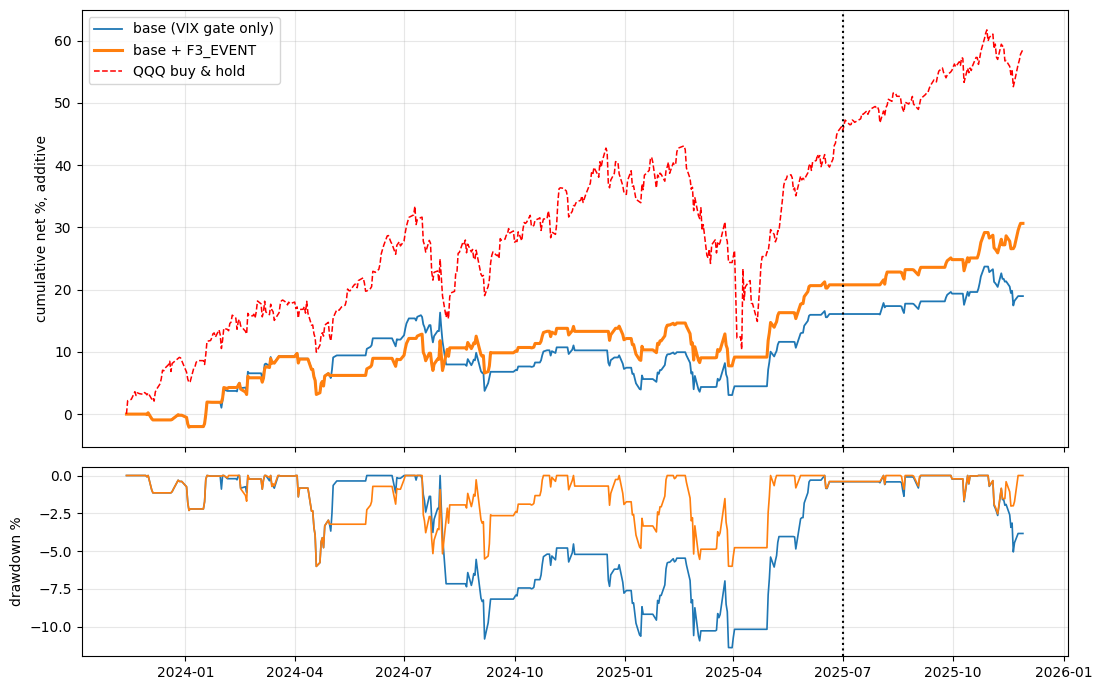

IS: base 52 trades, F3 51; identical entries 44; changed 7; base net $16,080 -> F3 $20,769
SELECTION: base 10 trades, F3 10; identical entries 7; changed 3; base net $2,879 -> F3 $9,873
IS net excluding the Aug-2024 entry: base $19,615 vs F3 $17,121


In [5]:
D, Tt = {}, {}
for name, key in (("base (VIX gate only)", None), ("base + F3_EVENT", "F3_EVENT")):
    ds, ts = [], []
    for s in STAGES:
        T, d, _ = run(s, None if key is None else masks[s][key]); ds.append(d); ts.append(T.assign(stage=s))
    D[name] = pd.concat(ds); Tt[name] = pd.concat(ts, ignore_index=True)
bh = pd.concat([E.benchmark_daily(bars[s], STAGES[s][0]) for s in STAGES])
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
for k, d in D.items():
    ax[0].plot(d.cumsum()/E.CAPITAL*100, label=k, lw=2.2 if "F3" in k else 1.3); eq = E.CAPITAL + d.cumsum(); ax[1].plot((eq-eq.cummax())/eq.cummax()*100, lw=1.2)
ax[0].plot(bh.cumsum()/E.CAPITAL*100, "r--", lw=1.1, label="QQQ buy & hold"); ax[0].legend(); ax[0].set_ylabel("cumulative net %, additive"); ax[1].set_ylabel("drawdown %")
for a_ in ax: a_.axvline(pd.Timestamp("2025-07-01"), color="k", ls=":"); a_.grid(alpha=.3)
plt.tight_layout(); plt.show()
for s in STAGES:
    b_, f_ = Tt["base (VIX gate only)"].query("stage==@s"), Tt["base + F3_EVENT"].query("stage==@s"); same = set(b_.entry_time) & set(f_.entry_time)
    print(f"{s}: base {len(b_)} trades, F3 {len(f_)}; identical entries {len(same)}; changed {len(f_)-len(same)}; base net ${b_.pnl_usd.sum():,.0f} -> F3 ${f_.pnl_usd.sum():,.0f}")
x = [(Tt[k].query("stage=='IS'")) for k in Tt]; m = [pd.to_datetime(t["entry_time"], utc=True) for t in x]
ex = [t.pnl_usd.sum() - t[(mm >= "2024-08-02") & (mm <= "2024-08-06")].pnl_usd.sum() for t, mm in zip(x, m)]
print(f"IS net excluding the Aug-2024 entry: base ${ex[0]:,.0f} vs F3 ${ex[1]:,.0f}")

## 5. Placebo (diagnostic only): block the same share of RANDOM entry days (300 draws here; the saved file used 1,000)

In [6]:
rng = np.random.default_rng(20261114); out = []
for s, (a, e) in STAGES.items():
    d_arr = bars[s]["day"].values; entry_day = np.append(d_arr[1:], d_arr[-1]); tm = d_arr >= np.datetime64(pd.Timestamp(a))
    days = pd.Series(d_arr[tm]).unique(); k = max(1, int(round((1 - masks[s]["F3_EVENT"][tm].mean()) * len(days))))
    f3 = E.metrics(*run(s, masks[s]["F3_EVENT"])[:2])["sharpe"]; sh = []
    for _ in range(300):
        blk = set(rng.choice(days, k, replace=False)); sh.append(E.metrics(*run(s, np.array([x not in blk for x in entry_day]))[:2])["sharpe"])
    out.append(dict(stage=s, F3_sharpe=round(f3, 3), placebo_median=round(float(np.median(sh)), 3), pct_placebo_at_least_F3=round(float((np.array(sh) >= f3).mean()*100), 1)))
pd.DataFrame(out)

,stage,F3_sharpe,placebo_median,pct_placebo_at_least_F3
0,IS,1.094,0.722,5.3
1,SELECTION,2.301,0.681,1.3


## 6. Limits
- The filter shifts only a few entries (7 of 52 in-sample, 3 of 10 in selection); the in-sample gain comes from one episode (the 2 Aug 2024 jobs-report entry).
- Four filters were tried and v1 had already shown IS and SELECTION, so the p-values are optimistic; 18 distinct configs in total.
- The economic calendar file ends 2026-11-05; event days for paper trading must be kept by hand from the public schedule.
- Out-of-sample has not been run. The holdout is frozen-rule, single-pass but not market-blind.